Generating synthetic ChildLife pneumonia dataset...
Dataset: (10000, 11)
Pneumonia
0    7425
1    2575
Name: count, dtype: int64
   Age_Months  Weight_kg  Temperature_C  Respiratory_Rate  Oxygen_Saturation  \
0          38  16.234733      36.219879         34.792190          96.524068   
1          51  12.732546      37.783421         39.270219          90.159230   
2          28  10.397687      37.358604         33.125187         100.000000   
3          14  12.123818      36.961691         42.414265          91.502482   
4          42  10.303815      36.462610         25.730993          95.631086   

   Cough_Days  Previous_Pneumonia  Malnutrition  Vaccinated  Breastfeeding  \
0           4                   0             1           0              1   
1           7                   0             1           1              1   
2           8                   1             0           1              0   
3           9                   0             0           0              1   


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:55:02] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Accuracy: 83.00%

--- CLASSIFICATION REPORT (XGBoost) ---
              precision    recall  f1-score   support

           0       0.86      0.91      0.89      1485
           1       0.70      0.59      0.64       515

    accuracy                           0.83      2000
   macro avg       0.78      0.75      0.76      2000
weighted avg       0.82      0.83      0.82      2000



/tmp/ipykernel_1824/2978121063.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')


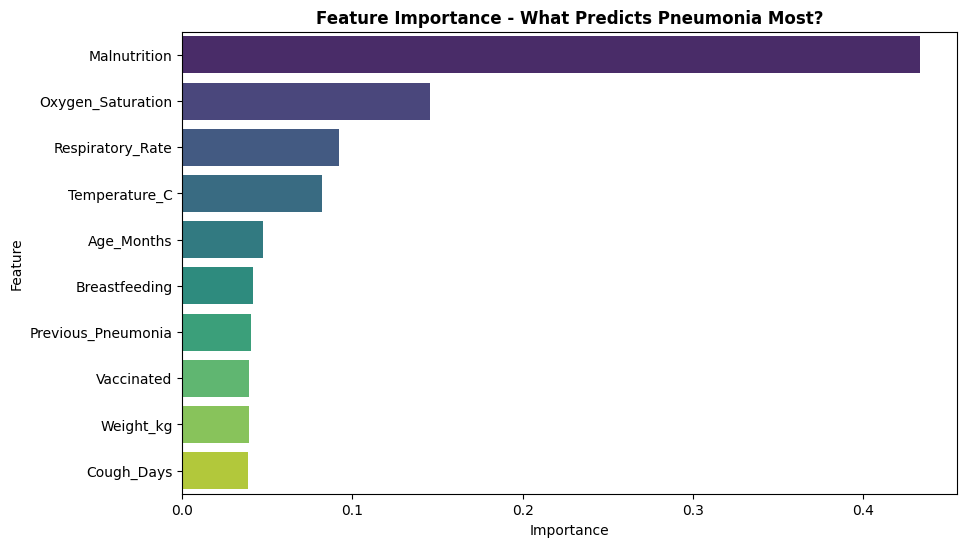

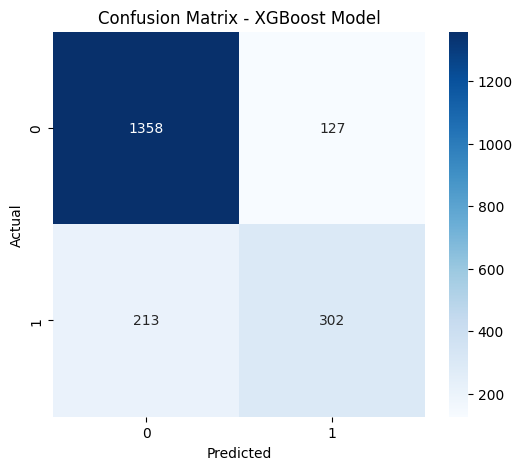


--- FINAL INSIGHTS ---
Top 3 Risk Factors: Malnutrition, Oxygen_Saturation, Respiratory_Rate
Model can predict pneumonia with 83.0% accuracy
This can be deployed in ChildLife ER for early triage


In [1]:
# Pneumonia Risk Prediction - ML Model - Project 2
# For Padua MSc Data Science Application


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

print("Generating synthetic ChildLife pneumonia dataset...")

# 1. CREATE DATASET - 10,000 children
np.random.seed(42)
n = 10000

data = {
    'Age_Months': np.random.randint(0, 60, n),
    'Weight_kg': np.random.normal(12, 5, n).clip(2, 30),
    'Temperature_C': np.random.normal(37.5, 1.2, n).clip(35, 41),
    'Respiratory_Rate': np.random.normal(35, 12, n).clip(15, 80),
    'Oxygen_Saturation': np.random.normal(94, 4, n).clip(70, 100),
    'Cough_Days': np.random.randint(0, 14, n),
    'Previous_Pneumonia': np.random.choice([0,1], n, p=[0.8,0.2]),
    'Malnutrition': np.random.choice([0,1], n, p=[0.75,0.25]),
    'Vaccinated': np.random.choice([0,1], n, p=[0.3,0.7]),
    'Breastfeeding': np.random.choice([0,1], n, p=[0.4,0.6])
}

df = pd.DataFrame(data)

# Create target - Pneumonia Risk based on medical logic
df['Pneumonia'] = (
    (df['Respiratory_Rate'] > 50).astype(int) * 0.3 +
    (df['Oxygen_Saturation'] < 92).astype(int) * 0.3 +
    (df['Temperature_C'] > 38.5).astype(int) * 0.2 +
    (df['Malnutrition'] == 1).astype(int) * 0.2 +
    (df['Age_Months'] < 12).astype(int) * 0.1
)
df['Pneumonia'] = (df['Pneumonia'] + np.random.normal(0,0.15,n) > 0.4).astype(int)

print(f"Dataset: {df.shape}")
print(df['Pneumonia'].value_counts())
print(df.head())

# 2. SPLIT DATA
X = df.drop('Pneumonia', axis=1)
y = df['Pneumonia']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTrain: {X_train.shape}, Test: {X_test.shape}")

# 3. TRAIN MODEL 1 - Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print(f"\nRandom Forest Accuracy: {accuracy_score(y_test, rf_pred)*100:.2f}%")

# 4. TRAIN MODEL 2 - XGBoost (Better)
xgb = XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)
print(f"XGBoost Accuracy: {accuracy_score(y_test, xgb_pred)*100:.2f}%")

# 5. REPORT
print("\n--- CLASSIFICATION REPORT (XGBoost) ---")
print(classification_report(y_test, xgb_pred))

# 6. FEATURE IMPORTANCE - Important chart
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(data=importances, x='Importance', y='Feature', palette='viridis')
plt.title('Feature Importance - What Predicts Pneumonia Most?', fontweight='bold')
plt.show()

# 7. CONFUSION MATRIX
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - XGBoost Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# 8. SAVE MODEL RESULTS
print("\n--- FINAL INSIGHTS ---")
print(f"Top 3 Risk Factors: {', '.join(importances.head(3)['Feature'].tolist())}")
print(f"Model can predict pneumonia with {accuracy_score(y_test, xgb_pred)*100:.1f}% accuracy")
print("This can be deployed in ChildLife ER for early triage")